In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import sys

# Estilo Visual
plt.rcdefaults()
plt.style.use('tableau-colorblind10')
%matplotlib widget 
plt.rcParams.update({
    'font.size': 10, 
    'text.color': 'black', 
    'axes.labelcolor': 'black', 
    'xtick.color': 'black', 
    'ytick.color': 'black'
})


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
--> Carregando dados de Fiducial_452Halos_FullSpectra.pkl (isso pode levar alguns segundos)...
--> Filtrando Halo Match Index 8...
--> Halo ID Real: 27798
--> Massa: 8.538e10 Msun/h
--> R200: 0.072 Mpc/h
--> Raios encontrados: [0.1        0.23403473 0.54772256 1.28186102 3.        ]
--> Plotando R = 0.10 x R200...


/tmp/ipykernel_2959180/1202737998.py:67: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(9, 5))


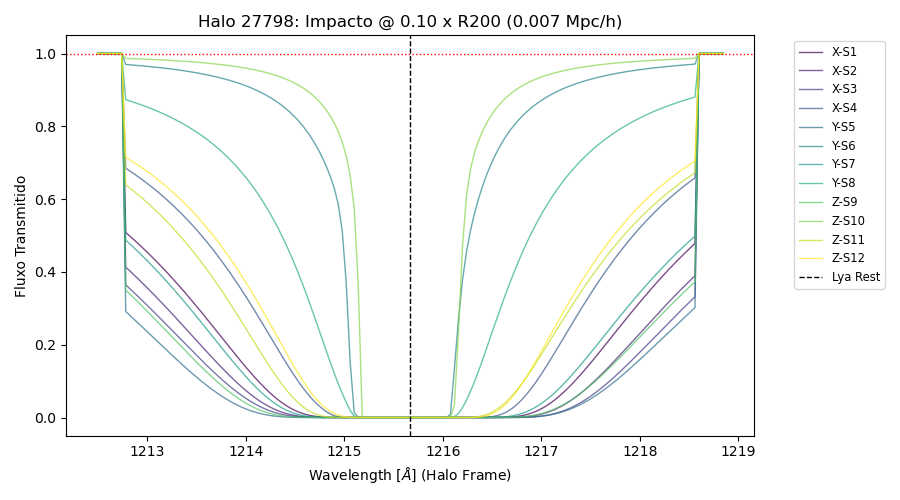

--> Plotando R = 0.23 x R200...


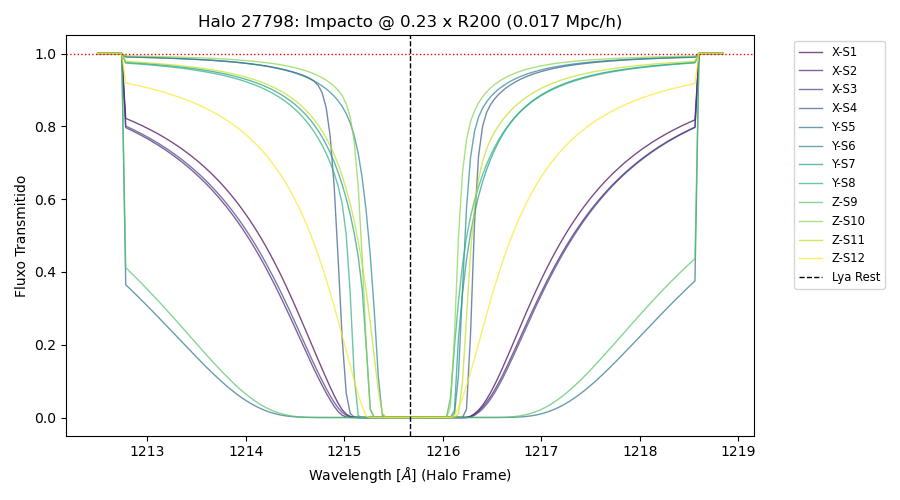

--> Plotando R = 0.55 x R200...


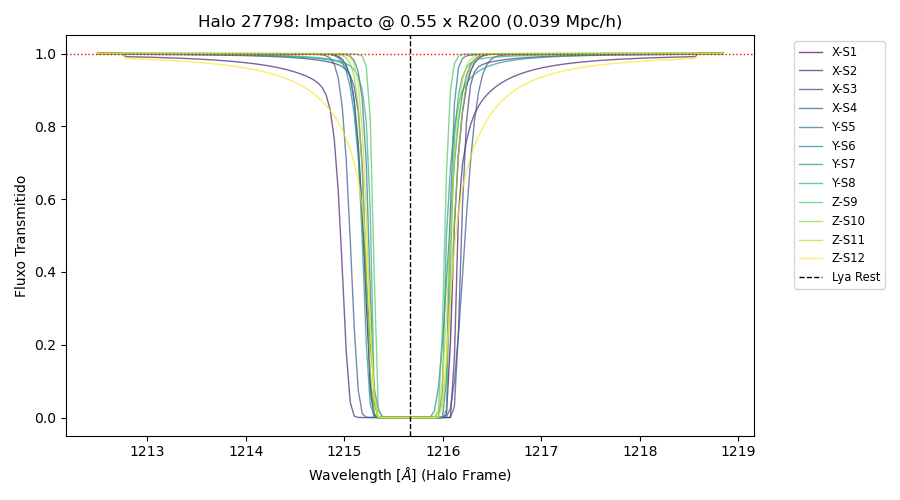

--> Plotando R = 1.28 x R200...


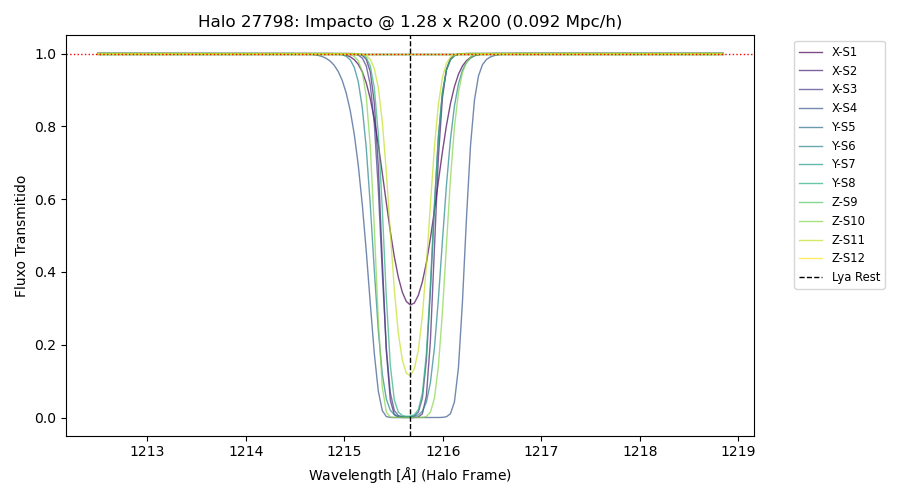

--> Plotando R = 3.00 x R200...


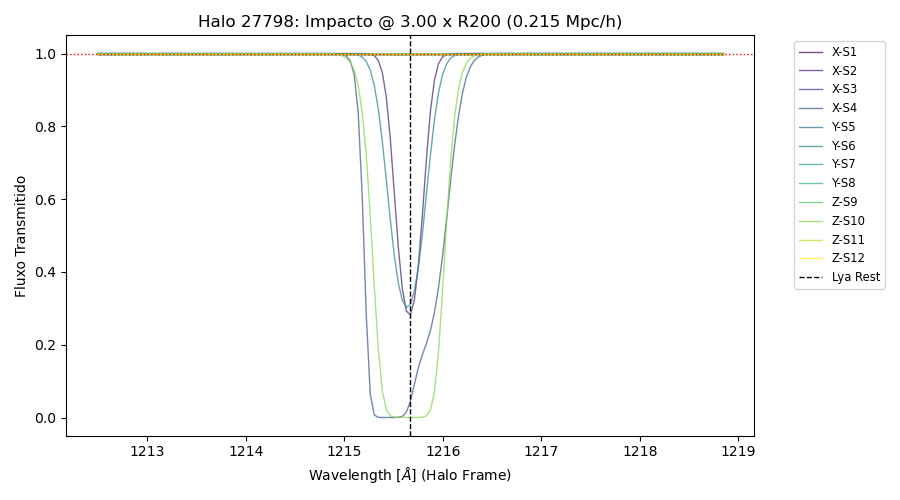

In [ ]:
# --- 1. CONFIGURAÇÃO ---
# Caminho para o arquivo GRANDE que você gerou com o run_parallel
INPUT_FILE = "Fiducial_452Halos_FullSpectra.pkl" 
# (Se estiver na mesma pasta do notebook, use apenas o nome do arquivo)

# O Halo que você quer visualizar
MATCH_INDEX = 8 

# --- 2. CARREGAR DADOS ---
if not os.path.exists(INPUT_FILE):
    print(f"ERRO: Não encontrei o arquivo {INPUT_FILE}. Verifique o caminho.")
else:
    print(f"--> Carregando dados de {INPUT_FILE} (isso pode levar alguns segundos)...")
    df_all = pd.read_pickle(INPUT_FILE)

    # --- 3. FILTRAR O HALO ESPECÍFICO ---
    print(f"--> Filtrando Halo Match Index {MATCH_INDEX}...")
    df_halo = df_all[df_all['match_index'] == MATCH_INDEX].copy()

    if df_halo.empty:
        print(f"AVISO: Halo {MATCH_INDEX} não encontrado no arquivo.")
    else:
        # Recuperar metadados do primeiro skewer (são iguais para todo o halo)
        real_halo_id = df_halo['halo_id'].iloc[0]
        halo_mass = df_halo['halo_mass'].iloc[0]
        r200_mpc = df_halo['halo_r200_mpc'].iloc[0]
        
        print(f"--> Halo ID Real: {real_halo_id}")
        print(f"--> Massa: {halo_mass:.3f}e10 Msun/h")
        print(f"--> R200: {r200_mpc:.3f} Mpc/h")

        # --- 4. PLOTAGEM (LOOP PELOS RAIOS DISPONÍVEIS) ---
        # Descobre quais raios existem no arquivo para este halo
        available_radii = np.sort(df_halo['r_multiplier'].unique())
        print(f"--> Raios encontrados: {available_radii}")

        for r_mult in available_radii:
            # Pega apenas os skewers deste raio
            subset = df_halo[df_halo['r_multiplier'] == r_mult]
            
            # Pega o impacto em Mpc para o título (convertendo de kpc)
            impact_mpc = subset['impact_kpc'].iloc[0] / 1000.0
            
            print(f"--> Plotando R = {r_mult:.2f} x R200...")
            
            fig, ax = plt.subplots(figsize=(9, 5))
            
            # Cores diferentes para cada skewer (normalmente são 12)
            colors = plt.cm.viridis(np.linspace(0, 1, len(subset)))
            
            # Loop sobre as linhas do DataFrame
            for i, (idx, row) in enumerate(subset.iterrows()):
                lbl = f"{row['axis_name']}-S{row['skewer_id']}"
                
                # Plotar Fluxo vs Wavelength
                # Nota: Se salvou como float32, o python plota normal
                ax.plot(row['wave'], row['flux'], color=colors[i], lw=1, alpha=0.7, label=lbl)

            # Linhas de referência
            ax.axvline(x=1215.67, color='k', linestyle='--', linewidth=1, label="Lya Rest")
            ax.axhline(y=1.0, color='r', linestyle=':', linewidth=1)
            
            # Formatação
            ax.set_xlabel(r"Wavelength [$\AA$] (Halo Frame)")
            ax.set_ylabel("Fluxo Transmitido")
            ax.set_title(f"Halo {real_halo_id}: Impacto @ {r_mult:.2f} x R200 ({impact_mpc:.3f} Mpc/h)")
            ax.set_ylim(-0.05, 1.05)
            
            # Legenda do lado de fora
            ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
            
            plt.tight_layout()
            plt.show()